In [2]:
# Imports et configuration
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Algorithmes de partitionnement et hiérarchiques
from sklearn.cluster import KMeans, BisectingKMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Préparation et réduction de dimension
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Métriques d'évaluation
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Configuration visuelle
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("imports et configuration fait avec succés")

imports et configuration fait avec succés


In [4]:
# Définition des variables attendues et validation automatique
EXPECTED_FEATURES = [
    'n_events', 'n_tx', 'n_login', 'n_failed',
    'n_new_device', 'n_foreign', 'pct_night', 'hour_mean',
    'amount_mean', 'amount_ratio', 'min_gap', 'mean_gap', 'amount_max'
]

METADATA_COLS = ['user_id', 'day']

def validate_input_data(df: pd.DataFrame) -> bool:
    """
    Vérifie la conformité de la structure des données :
    - Présence des identifiants (user_id, day)
    - Présence stricte des 13 indicateurs comportementaux
    - Contrôle des types numériques
    - Contrôle et signalement des valeurs manquantes (NaN)
    """
    missing_meta = [col for col in METADATA_COLS if col not in df.columns]
    missing_feats = [col for col in EXPECTED_FEATURES if col not in df.columns]
    
    if missing_meta:
        raise ValueError(f"Erreur schéma : colonnes d'identification manquantes -> {missing_meta}")
    if missing_feats:
        raise ValueError(f"Erreur schéma : variables manquantes -> {missing_feats}")
        
    # Vérification des types non numériques
    non_numeric = [col for col in EXPECTED_FEATURES if not pd.api.types.is_numeric_dtype(df[col])]
    if non_numeric:
        print(f"Attention : colonnes non numériques détectées -> {non_numeric}")
        
    # Contrôle des NaN
    nan_counts = df[EXPECTED_FEATURES].isna().sum()
    total_nans = nan_counts.sum()
    if total_nans > 0:
        print(f"Attention : {total_nans} valeurs manquantes détectées !")
        print(nan_counts[nan_counts > 0])
        return False
    
    print("Validation réussie : 13 features et métadonnées conformes, aucune valeur manquante.")
    return True

In [8]:
import os

# Remonte d'un niveau si nécessaire
if not os.path.exists("data/processed/features.csv"):
    path = "../data/processed/features.csv"
else:
    path = "data/processed/features.csv"

df = pd.read_csv(path)

print("Dataset chargé avec succès !")
print("Dimensions :", df.shape)

display(df.head())

Dataset chargé avec succès !
Dimensions : (30000, 16)


,user_id,day,is_attack,n_events,n_tx,n_login,n_failed,n_new_device,n_foreign,pct_night,hour_mean,amount_mean,amount_max,amount_ratio,min_gap,mean_gap
0,U0001,2026-01-01,0.0,1.650701,0.833335,1.899901,-0.170189,-0.077199,-0.077199,-0.351656,0.158908,1.494113,1.472459,1.333169,1.257253,1.233635
1,U0001,2026-01-02,0.0,-0.050755,0.833335,-1.008867,-0.170189,-0.077199,-0.077199,-0.351656,-0.088608,1.110378,1.092334,0.208452,-0.754072,-0.763833
2,U0001,2026-01-03,0.0,-0.050755,0.833335,-1.008867,-0.170189,-0.077199,-0.077199,-0.351656,-0.309011,1.388223,1.367566,0.957842,-0.754072,-0.763833
3,U0001,2026-01-04,0.0,0.702151,0.833335,0.445517,-0.170189,-0.077199,-0.077199,1.681502,0.890960,1.351546,1.331234,0.839547,1.824455,1.709015
4,U0001,2026-01-05,0.0,0.702151,0.833335,0.445517,-0.170189,-0.077199,-0.077199,-0.351656,0.822740,1.345525,1.325269,0.820704,1.336704,1.241254


In [9]:
# Validation du dataset

validate_input_data(df)

Validation réussie : 13 features et métadonnées conformes, aucune valeur manquante.


True

In [11]:
print(df.head())
print(df.shape)
print(df.info())
print(df.columns.tolist())

  user_id         day  is_attack  n_events      n_tx   n_login  n_failed  \
0   U0001  2026-01-01        0.0  1.650701  0.833335  1.899901 -0.170189   
1   U0001  2026-01-02        0.0 -0.050755  0.833335 -1.008867 -0.170189   
2   U0001  2026-01-03        0.0 -0.050755  0.833335 -1.008867 -0.170189   
3   U0001  2026-01-04        0.0  0.702151  0.833335  0.445517 -0.170189   
4   U0001  2026-01-05        0.0  0.702151  0.833335  0.445517 -0.170189   

   n_new_device  n_foreign  pct_night  hour_mean  amount_mean  amount_max  \
0     -0.077199  -0.077199  -0.351656   0.158908     1.494113    1.472459   
1     -0.077199  -0.077199  -0.351656  -0.088608     1.110378    1.092334   
2     -0.077199  -0.077199  -0.351656  -0.309011     1.388223    1.367566   
3     -0.077199  -0.077199   1.681502   0.890960     1.351546    1.331234   
4     -0.077199  -0.077199  -0.351656   0.822740     1.345525    1.325269   

   amount_ratio   min_gap  mean_gap  
0      1.333169  1.257253  1.233635  
1   

In [12]:
#Vérifier les valeurs manquantes
print(df.isnull().sum())
#Vérifier les doublons
print(df.duplicated(["user_id", "day"]).sum())
#Vérifier les valeurs infinies
numeric_df = df.select_dtypes(include=np.number)
print(np.isinf(numeric_df).sum())
#Vérifier la répartition des labels
print(df["is_attack"].value_counts())
print(df["is_attack"].value_counts(normalize=True) * 100)

user_id         0
day             0
is_attack       0
n_events        0
n_tx            0
n_login         0
n_failed        0
n_new_device    0
n_foreign       0
pct_night       0
hour_mean       0
amount_mean     0
amount_max      0
amount_ratio    0
min_gap         0
mean_gap        0
dtype: int64
0
is_attack       0
n_events        0
n_tx            0
n_login         0
n_failed        0
n_new_device    0
n_foreign       0
pct_night       0
hour_mean       0
amount_mean     0
amount_max      0
amount_ratio    0
min_gap         0
mean_gap        0
dtype: int64
is_attack
0.0    29700
1.0      300
Name: count, dtype: int64
is_attack
0.0    99.0
1.0     1.0
Name: proportion, dtype: float64


In [14]:
feature_columns = [
    "n_events",
    "n_tx",
    "n_login",
    "n_failed",
    "n_new_device",
    "n_foreign",
    "pct_night",
    "hour_mean",
    "amount_mean",
    "amount_max",
    "amount_ratio",
    "min_gap",
    "mean_gap"
]

#Séparer les données
X = df[feature_columns].copy()
y_true = df["is_attack"].copy()
metadata = df[["user_id", "day"]].copy()


In [15]:
# préparer K-Means
from sklearn.cluster import KMeans
import time

start = time.perf_counter()

kmeans = KMeans(
    n_clusters=4,
    init="random",
    n_init=10,
    max_iter=300,
    random_state=42
)

labels_kmeans = kmeans.fit_predict(X)

elapsed = time.perf_counter() - start

print("Temps :", elapsed)
print("Inertie :", kmeans.inertia_)
print("Itérations :", kmeans.n_iter_)

Temps : 0.3421593999955803
Inertie : 152316.51023044874
Itérations : 10


In [17]:
# CHOIX DE K:

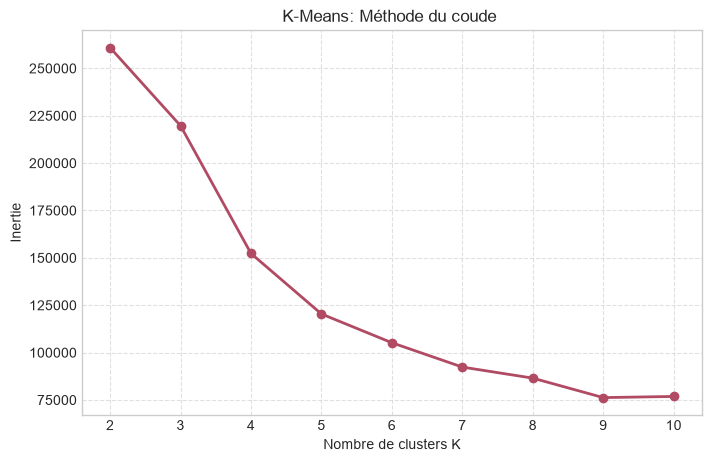

In [27]:
#methode du coude (elbow method)
inertias = []
k_values = range(2, 11)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        init="random",
        n_init=10,
        random_state=42
    )

    model.fit(X)

    inertias.append(model.inertia_)

#traçage du graphique
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o", color="#b14a63", linewidth=2)

plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie")
plt.title("K-Means: Méthode du coude ")
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig("../clustering/graphiques/coude_kmeans.png", dpi=300, bbox_inches="tight")
plt.show()


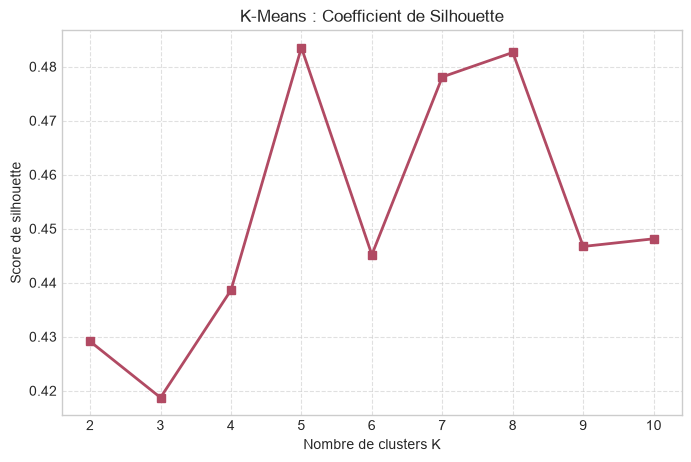

In [26]:
#Coefficient de silhouette
from sklearn.metrics import silhouette_score

silhouettes = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="random",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    silhouettes.append(score)


# Visualisation propre
plt.figure(figsize=(8, 5))
plt.plot(list(range(2, 11)), silhouettes, marker="s", color="#b14a63", linewidth=2)

plt.xlabel("Nombre de clusters K")
plt.ylabel("Score de silhouette")
plt.title("K-Means : Coefficient de Silhouette")
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig("../clustering/graphiques/silhouette_kmeans.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
#Détermination du meilleur K en combinant les deux méthodes
import pandas as pd
import time

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Valeurs de K à tester
k_values = range(2, 11)

results = []

for k in k_values:

    # Création du modèle K-Means
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    # Mesurer le temps d'exécution
    start = time.time()

    # Entraîner le modèle
    labels = model.fit_predict(X)

    end = time.time()
    execution_time = end - start

    # Calculer la silhouette
    silhouette = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    # Enregistrer les résultats
    results.append({
        "K": k,
        "Inertie": model.inertia_,
        "Silhouette": silhouette,
        "Temps (secondes)": execution_time
    })

# Afficher le tableau final
resultats_k = pd.DataFrame(results)

display(resultats_k.round(4))

,K,Inertie,Silhouette,Temps (secondes)
0,2,260945.3247,0.4291,0.0679
1,3,192972.0638,0.4339,0.0767
2,4,151758.0609,0.4327,0.0781
3,5,119654.2285,0.4773,0.0758
4,6,104630.4736,0.4952,0.0849
5,7,91649.3318,0.4711,0.1202
6,8,80729.4723,0.4728,0.1220
7,9,72523.1290,0.4921,0.1438
8,10,62018.6637,0.5117,0.1417


In [33]:
#Expérimenter K-Means++
kmeans_pp = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

start = time.perf_counter()

labels_kmeanspp = kmeans_pp.fit_predict(X)

time_kmeanspp = time.perf_counter() - start

print("Inertie :", kmeans_pp.inertia_)
print("Itérations :", kmeans_pp.n_iter_)
print("Temps :", time_kmeanspp)

Inertie : 119654.22848780919
Itérations : 4
Temps : 0.19089889992028475


In [34]:
seeds = [10, 20, 30, 40, 50]

results = []

for seed in seeds:

    for initialization in ["random", "k-means++"]:

        model = KMeans(
            n_clusters=5,
            init=initialization,
            n_init=1,
            random_state=seed
        )

        start = time.perf_counter()

        model.fit(X)

        elapsed = time.perf_counter() - start

        results.append({
            "seed": seed,
            "initialization": initialization,
            "inertia": model.inertia_,
            "iterations": model.n_iter_,
            "time": elapsed
        })

comparison_init = pd.DataFrame(results)

In [35]:
print(
    comparison_init.groupby("initialization")[
        ["inertia", "iterations", "time"]
    ].agg(["mean", "std"])
)

                      inertia               iterations                time  \
                         mean           std       mean       std      mean   
initialization                                                               
k-means++       123516.383730   5294.739906        3.2  1.095445  0.024747   
random          156182.564821  32585.212342       11.8  7.596052  0.025148   

                          
                     std  
initialization            
k-means++       0.005105  
random          0.005774  


In [37]:
#Premier score d'anomalie K-Means
#pour Kmeans:
from sklearn.metrics import pairwise_distances

distances = kmeans.transform(X)

labels = labels_kmeans

anomaly_score_kmeans = distances[
    np.arange(len(X)),
    labels
]

#pour kmeans++:
distances_pp = kmeans_pp.transform(X)

anomaly_score_kmeanspp = distances_pp[
    np.arange(len(X)),
    labels_kmeanspp
]

In [38]:
def percentile_anomaly_score(scores):

    return (
        pd.Series(scores)
        .rank(pct=True)
        .to_numpy()
    )

In [40]:
threshold = 0.98

# Flag pour K-Means
flag_kmeans = (
    anomaly_score_kmeans >= np.quantile(anomaly_score_kmeans, threshold)
).astype(int)

# Flag pour K-Means++
flag_kmeanspp = (
    anomaly_score_kmeanspp >= np.quantile(anomaly_score_kmeanspp, threshold)
).astype(int)

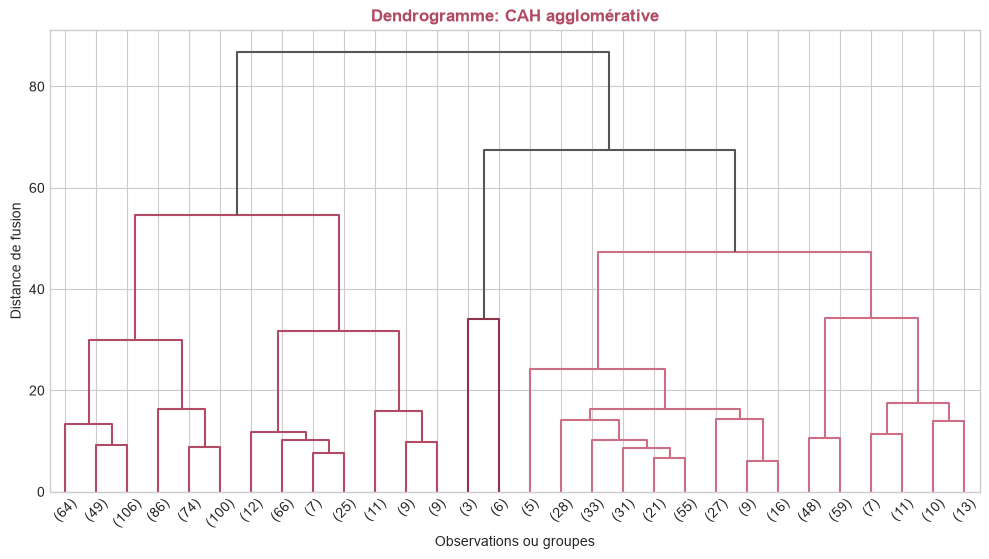

In [ ]:
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    set_link_color_palette
)
import matplotlib.pyplot as plt

sample_size = min(1000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=42
)

Z = linkage(
    X_sample,
    method="ward"
)

custom_palette = [
    "#b14a63",  
    "#8e344a",  
    "#cc6f85",  
    "#e298a8"   
]
set_link_color_palette(custom_palette)

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    above_threshold_color="#555555",  
    color_threshold=None             
)

# Réinitialise la palette par défaut de SciPy pour les futurs tracés
set_link_color_palette(None)

plt.title("Dendrogramme: CAH agglomérative", color="#b14a63", fontweight="bold")
plt.xlabel("Observations ou groupes")
plt.ylabel("Distance de fusion")

plt.savefig(
    "../clustering/graphiques/dendrogramme_cah.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
#Construire le graphe de voisinage
from sklearn.neighbors import kneighbors_graph

connectivity = kneighbors_graph(
    X,
    n_neighbors=15,
    include_self=False
)

In [47]:
#Exécuter la CAH sur toutes les observations
from sklearn.cluster import AgglomerativeClustering

cah_agglo = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward",
    connectivity=connectivity
)

start = time.perf_counter()

labels_agglo = cah_agglo.fit_predict(X)

time_agglo = time.perf_counter() - start

print("Temps :", time_agglo)

print(
    "Clusters :",
    np.unique(labels_agglo)
)

c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


Temps : 15.756713000009768
Clusters : [0 1 2 3 4]


In [48]:
#Tester plusieurs valeurs de K
k_values = range(2, 9)

agglo_results = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        connectivity=connectivity
    )

    start = time.perf_counter()

    labels = model.fit_predict(X)

    elapsed = time.perf_counter() - start

    score = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    db_score = davies_bouldin_score(
        X,
        labels
    )

    agglo_results.append({
        "k": k,
        "silhouette": score,
        "davies_bouldin": db_score,
        "time": elapsed
    })

agglo_results = pd.DataFrame(agglo_results)

c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(
c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(
c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(
c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_

In [50]:
#Calculer le score d'anomalie de la CAH agglomérative
#Calculer les centroïdes
centroids_agglo = {}

for cluster_id in np.unique(labels_agglo):

    cluster_points = X[
        labels_agglo == cluster_id
    ]

    centroids_agglo[cluster_id] = (
        cluster_points.mean(axis=0).values
    )

#Calculer les distances aux centroïdes
from scipy.spatial.distance import cdist

anomaly_score_agglo = np.zeros(len(X))

for cluster_id, centroid in centroids_agglo.items():

    indices = np.where(
        labels_agglo == cluster_id
    )[0]

    distances = cdist(
        X.iloc[indices],
        centroid.reshape(1, -1),
        metric="euclidean"
    ).ravel()

    anomaly_score_agglo[indices] = distances

#Normaliser
score_agglo = percentile_anomaly_score(
    anomaly_score_agglo
)
#determiner les flags
flag_agglo = (
    score_agglo >= 0.98
).astype(int)

In [51]:
#Importer la classe BisectingKMeans
from sklearn.cluster import BisectingKMeans
#Créer le modèle
cah_divisive = BisectingKMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42,
    bisecting_strategy="biggest_inertia"
)
#Entraîner le modèle
start = time.perf_counter()

labels_divisive = cah_divisive.fit_predict(X)

time_divisive = time.perf_counter() - start

print("Temps :", time_divisive)

print(
    "Inertie :",
    cah_divisive.inertia_
)


Temps : 0.2094651999650523
Inertie : 151758.87917232816


In [52]:
# Tester plusieurs nombres de clusters
divisive_results = []

for k in range(2, 9):

    model = BisectingKMeans(
        n_clusters=k,
        n_init=10,
        random_state=42,
        bisecting_strategy="biggest_inertia"
    )

    start = time.perf_counter()

    labels = model.fit_predict(X)

    elapsed = time.perf_counter() - start

    silhouette = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    db_score = davies_bouldin_score(
        X,
        labels
    )

    divisive_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette,
        "davies_bouldin": db_score,
        "time": elapsed
    })

divisive_results = pd.DataFrame(
    divisive_results
)

In [53]:
#Calculer les scores d'anomalie
distances_divisive = cdist(
    X,
    cah_divisive.cluster_centers_,
    metric="euclidean"
)

anomaly_score_divisive = distances_divisive[
    np.arange(len(X)),
    labels_divisive
]
score_divisive = percentile_anomaly_score(
    anomaly_score_divisive
)

flag_divisive = (
    score_divisive >= 0.98
).astype(int)